# 03 - Debate experiments (Specifications 4-8)

Protocol: round 0 = three independent justified answers (identical to notebook 02's samples 0-2).
Rounds 1-2 are **synchronous**: every agent gets its own previous response plus the other agents' previous responses
(anonymous, same snapshot) and must name one specific strength or weakness before revising.

* `free`: unrestricted discussion. `structured`: PROPOSED ANSWER / SUPPORTING ARGUMENT / CRITICISM OF ALTERNATIVE / FINAL ANSWER.
  Same word limit and `max_tokens` for both free and structured.
* Final decision: majority vote vs. an LLM judge that sees the anonymised, shuffled final arguments and never the gold answer.
* Everything is compared with independent voting and with budget-matched baselines (self-revision, more independent samples).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loader, metrics, prompts
config.ensure_dirs()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SPLIT = "test"   #"dev" for development (100 questions from validation split); "test" for the testing (300 questions from test split)
print("model:", config.MODEL, "| server:", config.BASE_URL)

model: gemma2:9b | server: http://localhost:11434/v1


In [2]:
from src.debate_engine import (run_dataset, run_debate, debate_name, transcript_path, load_records, render_transcript)
from src.llm_client import LLMClient

client = LLMClient()
questions = data_loader.load_sampled(SPLIT)
qids = [q.id for q in questions]
cfg = config.DebateConfig()         
print(cfg)

by_qid = lambda recs: {r["qid"]: r for r in recs}
single_direct = by_qid(load_records(transcript_path(SPLIT, "single_direct")))
single_just = by_qid(load_records(transcript_path(SPLIT, "single_justify")))
ind = by_qid(load_records(transcript_path(SPLIT, "independent_justify")))
assert ind, "run notebook 02 first"

# in-context learning (ICL) example set should not overlap with dev/test questions
leaks = prompts.check_icl_leakage([q.question for q in data_loader.load_sampled("dev") + data_loader.load_sampled("test")])
assert not leaks, f"few-shot example overlaps with dataset questions: {leaks}"
print("ICL example set:", prompts.ICL_VERSION, "| no overlap with dev/test")

DebateConfig(n_agents=3, max_rounds=2, protocol='structured', early_stop=False, judge_final=True, judge_round0=True)
ICL example set: 1 | no overlap with dev/test


### Specification 4 & 5 - run debate (free vs structured)

In [3]:
debate = {}
VARIANTS = [("free", False), ("free", True), ("structured", False), ("structured", True)]
LABELS = {"free": "free", "free_icl": "free + ICL", "structured": "structured", "structured_icl": "structured + ICL"}

for protocol, icl in VARIANTS:
    key = f"{protocol}_icl" if icl else protocol
    recs = run_dataset(
        lambda q, p=protocol, ic=icl: run_debate(client, q, p, n_agents=cfg.n_agents, rounds=cfg.max_rounds,
                                         early_stop=cfg.early_stop, judge_final=cfg.judge_final,
                                         judge_round0=cfg.judge_round0, icl=ic),
        questions, transcript_path(SPLIT, debate_name(protocol, icl)),
        expect={"icl": icl, "icl_version": prompts.ICL_VERSION if icl else None})
    debate[key] = by_qid(recs)
print(client.stats)

for key in debate:
    assert all(debate[key][i]["answers_by_round"][0] == ind[i]["answers"][:cfg.n_agents] for i in qids)
print("round 0 of all 4 variants == independent samples 0-2")

test_debate_free: 0it [00:00, ?it/s]

test_debate_free_icl: 0it [00:00, ?it/s]

test_debate_structured: 0it [00:00, ?it/s]

test_debate_structured_icl: 0it [00:00, ?it/s]

{'calls': 0, 'cached_calls': 0, 'input_tokens': 0, 'output_tokens': 0}
round 0 of all 4 variants == independent samples 0-2


In [4]:
# readable transcript of one question where agents initially disagreed
ex = next((debate["structured"][i] for i in qids if not metrics.is_unanimous(debate["structured"][i]["answers_by_round"][0])), debate["structured"][qids[0]])
print(render_transcript(ex)[:3500])

# Mercury_7034843  (gold: B, mode: debate_structured)

## round 0 · agent · agent 0 → answer B  (122+52 tok, 11.52s)

Elements on the left side of the periodic table are generally metals, while those on the right are nonmetals. This fundamental difference stems from how their electrons are arranged and their tendency to gain or lose electrons during chemical reactions. 

Answer: B

## round 0 · agent · agent 1 → answer A  (122+67 tok, 14.84s)

Elements on the left side of the Periodic Table are generally metals, while those on the right are nonmetals.  Metals tend to lose electrons to form positive ions, while nonmetals tend to gain electrons to form negative ions. This difference in electron behavior is a fundamental property related to their atomic structure.

Answer: A

## round 0 · agent · agent 2 → answer B  (122+47 tok, 12.52s)

Elements on the left side of the periodic table are generally metals, while those on the right are nonmetals. This difference stems from their varying el

### Round-by-round analysis

--- free ---
 round  majority_acc  mean_agent_acc  pairwise_disagreement  unanimous_rate  unanimous_wrong_rate  unanimous_correct_rate  unparsed_rate
     0         0.893           0.893                  0.060           0.913                 0.060                   0.853          0.001
     1         0.897           0.899                  0.043           0.937                 0.067                   0.870          0.000
     2         0.910           0.904                  0.024           0.963                 0.080                   0.883          0.000
--- free_icl ---
 round  majority_acc  mean_agent_acc  pairwise_disagreement  unanimous_rate  unanimous_wrong_rate  unanimous_correct_rate  unparsed_rate
     0         0.893           0.893                  0.060           0.913                 0.060                   0.853          0.001
     1         0.893           0.876                  0.084           0.873                 0.067                   0.807          0.000
     2     

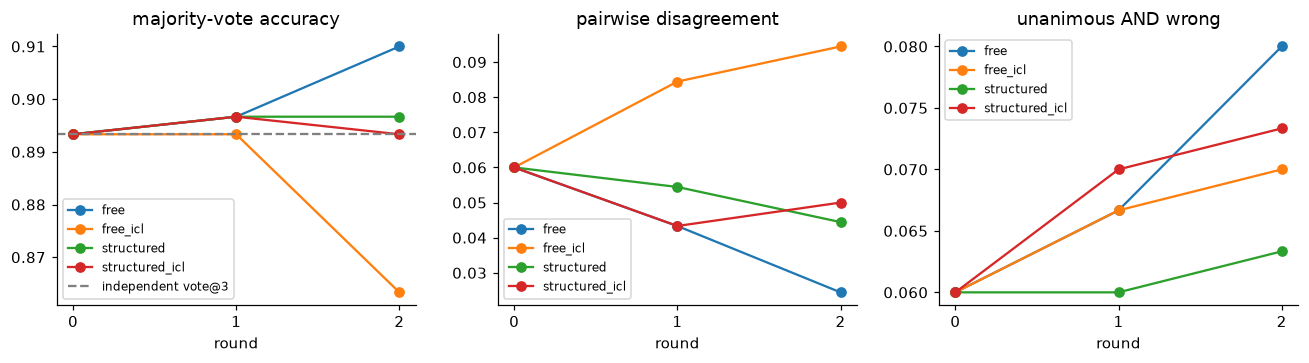

In [5]:
rs = {p: pd.DataFrame(metrics.round_summary([debate[p][i] for i in qids])) for p in debate}
for p, t in rs.items():
    print(f"--- {p} ---"); print(t.round(3).to_string(index=False))
    t.round(4).to_csv(config.TABLES_DIR / f"{SPLIT}_rounds_{p}.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for p, t in rs.items():
    ax[0].plot(t["round"], t["majority_acc"], marker="o", label=p)
    ax[1].plot(t["round"], t["pairwise_disagreement"], marker="o", label=p)
    ax[2].plot(t["round"], t["unanimous_wrong_rate"], marker="o", label=p)
ind_acc = np.mean([metrics.is_correct(metrics.vote_at_k(ind[i], 3)["answer"], ind[i]["gold"]) for i in qids])
ax[0].axhline(ind_acc, ls="--", c="gray", label="independent vote@3")
for a, t in zip(ax, ["majority-vote accuracy", "pairwise disagreement", "unanimous AND wrong"]):
    a.set(xlabel="round", title=t, xticks=range(cfg.max_rounds + 1)); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(config.PLOTS_DIR / f"03_{SPLIT}_rounds.png"); plt.show()

### Comparism between free(unrestricted) vs structured: accuracy, length, format compliance

In [6]:
def final_correct(p, decide="majority"):
    out = []
    for i in qids:
        r = debate[p][i]
        ans = metrics.majority_vote(metrics.padded_trajectory(r)[-1], i)["answer"] if decide == "majority" else r["judge_final"]["answer"]
        out.append(metrics.is_correct(ans, r["gold"]))
    return np.array(out)

for a, b in (("free", "structured"), ("free", "free_icl"), ("structured", "structured_icl"), ("free_icl", "structured_icl")):
    print(f"{b} vs {a} (majority after debate):", metrics.mcnemar_exact(final_correct(a), final_correct(b)))

len_rows = []
for p in debate:
    for rnd in range(0, cfg.max_rounds + 1):
        calls = [c for i in qids for c in debate[p][i]["calls"] if c["role"] == "agent" and c["round"] == rnd]
        words = [len(c["text"].split()) for c in calls]
        row = {"protocol": p, "round": rnd, "mean_output_tokens": np.mean([c["output_tokens"] for c in calls]),
               "mean_words": np.mean(words), "max_words": max(words),
               "truncated": np.mean([c["stop_reason"] == "max_tokens" for c in calls]),
               "unparsed": np.mean([c["answer"] is None for c in calls]),
               "max_input_tokens": max(c["input_tokens"] for c in calls)}
        if "structured" in p and rnd > 0:
            row["all_4_fields"] = np.mean([len(metrics.parse_structured(c["text"])) == 4 for c in calls])
        len_rows.append(row)
pd.DataFrame(len_rows).round(3)

structured vs free (majority after debate): {'a_only': 5, 'b_only': 1, 'delta_acc_b_minus_a': -0.01333333333333342, 'p_value': 0.21875}
free_icl vs free (majority after debate): {'a_only': 19, 'b_only': 5, 'delta_acc_b_minus_a': -0.046666666666666745, 'p_value': 0.006610751152038574}
structured_icl vs structured (majority after debate): {'a_only': 7, 'b_only': 6, 'delta_acc_b_minus_a': -0.0033333333333332993, 'p_value': 1.0}
structured_icl vs free_icl (majority after debate): {'a_only': 7, 'b_only': 16, 'delta_acc_b_minus_a': 0.030000000000000027, 'p_value': 0.0931396484375}


,protocol,round,mean_output_tokens,mean_words,max_words,truncated,unparsed,max_input_tokens,all_4_fields
0,free,0,53.578,39.896,85,0.0,0.001,239,NaN
1,free,1,53.331,37.788,68,0.0,0.000,581,NaN
2,free,2,53.303,37.080,60,0.0,0.000,445,NaN
3,free_icl,0,53.578,39.896,85,0.0,0.001,239,NaN
4,free_icl,1,60.770,44.891,87,0.0,0.000,1773,NaN
5,free_icl,2,61.704,44.601,82,0.0,0.000,1685,NaN
6,structured,0,53.578,39.896,85,0.0,0.001,239,NaN
7,structured,1,78.436,53.984,98,0.0,0.000,618,1.0
8,structured,2,79.493,55.186,84,0.0,0.000,586,1.0
9,structured_icl,0,53.578,39.896,85,0.0,0.001,239,NaN


### Specification 6 - final decision methods

Compared on the *same* final-round arguments: plurality vote (hash tie-break) vs. LLM judge.
`judge on round 0` is the control from the baseline

In [7]:
for p in debate:
    d = metrics.decision_comparison([debate[p][i] for i in qids])
    rows = d.pop("rows")
    print(f"--- {p}: vote vs judge on final-round arguments ---")
    print(pd.Series(d).to_string())
    print("paired test judge vs majority:", metrics.mcnemar_exact(final_correct(p, "majority"), final_correct(p, "judge")))
    j0 = np.array([metrics.is_correct(debate[p][i]["judge_round0"]["answer"], debate[p][i]["gold"]) for i in qids])
    v0 = np.array([metrics.is_correct(metrics.vote_at_k(ind[i], 3)["answer"], ind[i]["gold"]) for i in qids])
    print(f"judge on round-0 (no debate) accuracy {j0.mean():.3f} vs independent vote@3 {v0.mean():.3f}; outcome differs on "
          f"{np.mean([debate[p][i]['judge_round0']['answer'] != metrics.vote_at_k(ind[i], 3)['answer'] for i in qids]):.1%} of questions\n")
    pd.DataFrame(rows).to_csv(config.TABLES_DIR / f"{SPLIT}_decision_{p}.csv", index=False)

--- free: vote vs judge on final-round arguments ---
n                        300.000000
majority_acc               0.910000
judge_acc                  0.900000
outcome_changed            5.000000
outcome_changed_rate       0.016667
judge_fixes_majority       1.000000
judge_breaks_majority      4.000000
both_wrong_but_differ      0.000000
paired test judge vs majority: {'a_only': 4, 'b_only': 1, 'delta_acc_b_minus_a': -0.010000000000000009, 'p_value': 0.375}
judge on round-0 (no debate) accuracy 0.900 vs independent vote@3 0.893; outcome differs on 1.3% of questions

--- free_icl: vote vs judge on final-round arguments ---
n                        300.000000
majority_acc               0.863333
judge_acc                  0.856667
outcome_changed           11.000000
outcome_changed_rate       0.036667
judge_fixes_majority       4.000000
judge_breaks_majority      6.000000
both_wrong_but_differ      1.000000
paired test judge vs majority: {'a_only': 6, 'b_only': 4, 'delta_acc_b_minus_a': 

### Specification 7 - Answer-change analysis

Every rate is printed as `numerator/denominator`. 

In [8]:
def show_changes(rows):
    t = pd.DataFrame(rows)
    t["value"] = [f"{n}/{d} ({r:.1%})" if d else f"{n}/{d} (n/a)" for n, d, r in zip(t.num, t.den, t.rate)]
    return t[["metric", "value", "denominator"]]

changes = {}
for p in debate:
    recs = [debate[p][i] for i in qids]
    changes[p] = metrics.answer_change_rows(recs, 0, -1)
    pd.DataFrame(changes[p]).to_csv(config.TABLES_DIR / f"{SPLIT}_changes_{p}_overall.csv", index=False)
    print(f"--- {p}: round 0 -> final ---")
    print(show_changes(changes[p]).to_string(index=False))

--- free: round 0 -> final ---
                                                   metric         value                                       denominator
                               Agent correct -> incorrect  5/804 (0.6%)                        of agents correct at start
                               Agent incorrect -> correct 15/96 (15.6%)                      of agents incorrect at start
                                     Agent changed answer 22/900 (2.4%)                                     of all agents
                       Majority vote correct -> incorrect  0/268 (0.0%)           of questions with correct vote at start
                       Majority vote incorrect -> correct  5/32 (15.6%)         of questions with incorrect vote at start
               Correct minority: group vote correct after  4/11 (36.4%)              of questions with a correct minority
                Correct minority: unanimous correct after   1/11 (9.1%)              of questions with a correct mi

In [9]:
for p in debate:
    for r, rows in metrics.per_round_answer_changes([debate[p][i] for i in qids]).items():
        print(f"--- {p}: round {r-1} -> {r} ---")
        print(show_changes(rows).head(6).to_string(index=False))
        pd.DataFrame(rows).to_csv(config.TABLES_DIR / f"{SPLIT}_changes_{p}_r{r}.csv", index=False)

--- free: round 0 -> 1 ---
                                    metric        value                               denominator
                Agent correct -> incorrect 1/804 (0.1%)                of agents correct at start
                Agent incorrect -> correct  6/96 (6.2%)              of agents incorrect at start
                      Agent changed answer 9/900 (1.0%)                             of all agents
        Majority vote correct -> incorrect 0/268 (0.0%)   of questions with correct vote at start
        Majority vote incorrect -> correct  1/32 (3.1%) of questions with incorrect vote at start
Correct minority: group vote correct after  1/11 (9.1%)      of questions with a correct minority
--- free: round 1 -> 2 ---
                                    metric         value                               denominator
                Agent correct -> incorrect  4/809 (0.5%)                of agents correct at start
                Agent incorrect -> correct   9/91 (9.9%)      

### Specification 8 - Quality-cost comparison


In [10]:
selfrev = by_qid(load_records(transcript_path(SPLIT, "selfrevise")))
if not selfrev:
    from src.debate_engine import run_self_revision
    selfrev = by_qid(run_dataset(lambda q: run_self_revision(client, q, cfg.max_rounds), questions, transcript_path(SPLIT, "selfrevise")))

methods = {}  
def add(name, fn):
    methods[name] = [fn(i) for i in qids]

def pq(correct, us, dis=np.nan, ans_changed=np.nan):
    return {"correct": bool(correct), "tokens": us["total_tokens"], "lat_sum": us["latency_sum_s"], "lat_crit": us["latency_critical_s"], "dis": dis, "ans_changed": ans_changed}

ok = metrics.is_correct
add("single direct", lambda i: pq(ok(single_direct[i]["answer"], single_direct[i]["gold"]), metrics.usage(single_direct[i]["calls"])))
add("single justified", lambda i: pq(ok(single_just[i]["answer"], single_just[i]["gold"]), metrics.usage(single_just[i]["calls"])))
add("independent vote@3", lambda i: pq(ok(metrics.vote_at_k(ind[i], 3)["answer"], ind[i]["gold"]), metrics.usage(ind[i]["calls"], agents=range(3)),
                                       metrics.pairwise_disagreement(ind[i]["answers"][:3])))
d0 = debate["structured"]
add("independent x3 + judge", lambda i: pq(ok(d0[i]["judge_round0"]["answer"], d0[i]["gold"]),
                                           metrics.usage(d0[i]["calls"], rounds=[0], roles=["agent", "judge_round0"]),
                                           metrics.pairwise_disagreement(d0[i]["answers_by_round"][0])))
add("self-revision (2 rounds)", lambda i: pq(ok(selfrev[i]["answers_by_round"][-1][0], selfrev[i]["gold"]), metrics.usage(selfrev[i]["calls"]), ans_changed=float(selfrev[i]["answers_by_round"][-1][0] != selfrev[i]["answers_by_round"][0][0])))

for p in debate:
    D = debate[p]
    label = LABELS.get(p, p)
    fin = lambda i, D=D: metrics.padded_trajectory(D[i])[-1]
    def change_rate(i, D=D, fin=fin):
        r0 = D[i]["answers_by_round"][0]
        rf = fin(i)
        return np.mean([a != b for a, b in zip(r0, rf)])

    add(f"debate-{label} + majority", lambda i, D=D, fin=fin, change_rate=change_rate: pq(
        ok(metrics.majority_vote(fin(i), i)["answer"], D[i]["gold"]),
        metrics.usage(D[i]["calls"], roles=["agent"]), metrics.pairwise_disagreement(fin(i)), ans_changed=change_rate(i)))
    add(f"debate-{label} + judge", lambda i, D=D, fin=fin, change_rate=change_rate: pq(
        ok(D[i]["judge_final"]["answer"], D[i]["gold"]),
        metrics.usage(D[i]["calls"], roles=["agent", "judge_final"]), metrics.pairwise_disagreement(fin(i)), ans_changed=change_rate(i)))
    

vote3 = np.array([m["correct"] for m in methods["independent vote@3"]])
rows = []
for name, ms in methods.items():
    c = np.array([m["correct"] for m in ms]); mean, lo, hi = metrics.bootstrap_ci(c)
    t = metrics.mcnemar_exact(vote3, c)
    rows.append({"method": name, "accuracy": mean,
                 "disagreement": np.nanmean([m["dis"] for m in ms]) if not np.all(np.isnan([m["dis"] for m in ms])) else np.nan,
                 "answer_change_rate": np.nanmean([m["ans_changed"] for m in ms]) if not np.all(np.isnan([m["ans_changed"] for m in ms])) else np.nan,
                 "tokens/q": np.mean([m["tokens"] for m in ms]),
                 "latency": np.mean([m["lat_crit"] for m in ms])})
results = pd.DataFrame(rows).round(4)
results.to_csv(config.TABLES_DIR / f"{SPLIT}_comparison.csv", index=False)
results

,method,accuracy,disagreement,answer_change_rate,tokens/q,latency
0,single direct,0.8833,NaN,NaN,133.5333,1.5895
1,single justified,0.9033,NaN,NaN,194.8600,6.7519
2,independent vote@3,0.8933,0.0600,NaN,582.3333,13.0004
3,independent x3 + judge,0.9000,0.0600,NaN,1009.5333,23.4170
4,self-revision (2 rounds),0.7567,NaN,0.2200,725.7533,21.5149
5,debate-free + majority,0.9100,0.0244,0.0244,2984.0367,42.2204
6,debate-free + judge,0.9000,0.0244,0.0244,3408.9233,52.5046
7,debate-free + ICL + majority,0.8633,0.0944,0.1011,10250.4967,57.8976
8,debate-free + ICL + judge,0.8567,0.0944,0.1011,10700.8900,71.6246
9,debate-structured + majority,0.8967,0.0444,0.0122,3585.8500,56.9553


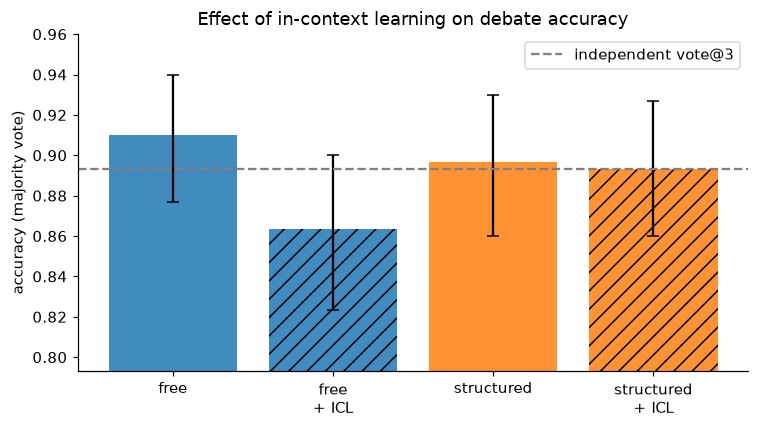

,protocol,acc without ICL,acc with ICL,fixed by ICL,broken by ICL,p (McNemar),agent correct->incorrect (without),(with),agent incorrect->correct (without),(with)
0,free,0.9100,0.8633,5,19,0.0066,5/804 (0.6%),59/804 (7.3%),15/96 (15.6%),28/96 (29.2%)
1,structured,0.8967,0.8933,6,7,1.0000,3/804 (0.4%),28/804 (3.5%),6/96 (6.2%),25/96 (26.0%)


In [11]:
# effect of the in-context examples: majority-vote accuracy after debate with 95% CI, and paired comparisons
order = ["free", "free_icl", "structured", "structured_icl"]
colors = {"free": "tab:blue", "structured": "tab:orange"}
fig, ax = plt.subplots(figsize=(7, 4)); los, his = [], []
for k, p in enumerate(order):
    m, lo, hi = metrics.bootstrap_ci(final_correct(p)); los.append(lo); his.append(hi)
    ax.bar(k, m, color=colors[p.split("_")[0]], hatch="//" if p.endswith("_icl") else None, alpha=0.85)
    ax.errorbar(k, m, yerr=[[m - lo], [hi - m]], color="black", capsize=4)
ax.axhline(vote3.mean(), ls="--", c="gray", label="independent vote@3")
ax.set(xticks=range(len(order)), xticklabels=[LABELS[p].replace(" + ", "\n+ ") for p in order], ylabel="accuracy (majority vote)",
       ylim=(max(0, min(los) - 0.03), min(1.0, max(his) + 0.02)), title="Effect of in-context learning on debate accuracy")
ax.legend(); plt.tight_layout(); plt.savefig(config.PLOTS_DIR / f"03_{SPLIT}_icl_effect.png", dpi=150); plt.show()

rate = lambda k, name: next(f"{r['num']}/{r['den']} ({r['rate']:.1%})" for r in changes[k] if r["metric"] == name)
rows = []
for base in ("free", "structured"):
    v = f"{base}_icl"
    t = metrics.mcnemar_exact(final_correct(base), final_correct(v))
    rows.append({"protocol": base, "acc without ICL": final_correct(base).mean(), "acc with ICL": final_correct(v).mean(),
                 "fixed by ICL": t["b_only"], "broken by ICL": t["a_only"], "p (McNemar)": round(t["p_value"], 4),
                 "agent correct->incorrect (without)": rate(base, "Agent correct -> incorrect"), "(with)": rate(v, "Agent correct -> incorrect"),
                 "agent incorrect->correct (without)": rate(base, "Agent incorrect -> correct"), "(with) ": rate(v, "Agent incorrect -> correct")})
icl_table = pd.DataFrame(rows).round(4)
icl_table.to_csv(config.TABLES_DIR / f"{SPLIT}_icl_vs_no_icl.csv", index=False)
icl_table

#### Manual inspection

In [12]:
kinds = ("useful_criticism", "unsupported_persuasion", "repeated_argument")
for p in debate:
    recs = [debate[p][i] for i in qids]
    examples = []
    for kind in kinds:
        ex = metrics.find_examples(recs, kind, k=8, seed=config.SEED)
        print(f"{p:10s} {kind:24s} candidates: {len(ex)}")
        examples += ex
    path = config.TABLES_DIR / f"{SPLIT}_inspection_{p}.csv"
    if path.exists() and (pd.read_csv(path).fillna("").get("label", pd.Series(dtype=str)).astype(str).str.strip() != "").any():
        print(f"{p}: {path.name} already contains labels")
        continue
    table = pd.DataFrame(examples).assign(label="", notes="")
    table.to_csv(path, index=False)
print("\nSaved results/tables/*_inspection_*.csv")


t = pd.read_csv(config.TABLES_DIR / f"{SPLIT}_inspection_structured.csv").fillna("")
for kind in kinds:
    row = t[t.kind == kind].head(1)
    if row.empty: continue
    r = row.iloc[0]
    print(f"\n===== {kind}: {r.qid} agent {r.agent} round {r['round']} | gold {r.gold} | {r.answers_before} -> {r.answers_after}")
    print("PREVIOUS:", r.previous_text[:500]); print("NEW:", r.new_text[:500])

free       useful_criticism         candidates: 8
free       unsupported_persuasion   candidates: 5
free       repeated_argument        candidates: 8
free_icl   useful_criticism         candidates: 8
free_icl   unsupported_persuasion   candidates: 8
free_icl   repeated_argument        candidates: 7
structured useful_criticism         candidates: 6
structured unsupported_persuasion   candidates: 2
structured repeated_argument        candidates: 8
structured_icl useful_criticism         candidates: 8
structured_icl unsupported_persuasion   candidates: 8
structured_icl repeated_argument        candidates: 8

Saved results/tables/*_inspection_*.csv

===== useful_criticism: Mercury_411729 agent 2 round 1 | gold B | ['B', 'B', 'A'] -> ['B', 'B', 'B']
PREVIOUS: Chlorine (Cl) has 17 protons.  To have one more proton, the element would need to have 18 protons.  

Answer: A
NEW: PROPOSED ANSWER: B
SUPPORTING ARGUMENT:  While both Sulfur (S) and Bromine (Br) have more protons than Chlorine (Cl), 

In [16]:
# after labelling: counts per kind x label
import glob
frames = [pd.read_csv(f).assign(protocol=Path(f).stem.split("inspection_", 1)[1]) for f in glob.glob(str(config.TABLES_DIR / f"{SPLIT}_inspection_*.csv"))]
lab = pd.concat(frames, ignore_index=True).fillna("") if frames else pd.DataFrame()
lab = lab[lab.label != ""] if not lab.empty else lab
print(pd.crosstab([lab.protocol, lab.kind], lab.label) if not lab.empty else "no labels filled in yet")

label                                  no-change  peer-pressure  specific-and-correct
protocol       kind                                                                  
free           repeated_argument               8              0                     0
               unsupported_persuasion          0              5                     0
               useful_criticism                0              0                     8
free_icl       repeated_argument               7              0                     0
               unsupported_persuasion          0              8                     0
               useful_criticism                0              0                     8
structured     repeated_argument               8              0                     0
               unsupported_persuasion          0              2                     0
               useful_criticism                0              0                     6
structured_icl repeated_argument               8      